# **Forecasting model of Bitcoin Price Prediction based on Time Series**

In [ ]:
# Utilities

import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import matplotlib.dates as mdates

# Packages for time series data prediction
# Statmodels is a reference library for time series analysis and statistical packages

import statsmodels.api as sm
import statsmodels.tsa.api as smt
import statsmodels.formula.api as smf

# Import the class for building autoregressive models (linear regression with a time variable)
from statsmodels.tsa.arima.model import ARIMA

# Metrics
from sklearn.metrics import mean_squared_error

# Utilities for printing multiple outputs in the same cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

In [ ]:
# Read the dataset, assigning the path where it is located
df = pd.read_csv('https://raw.githubusercontent.com/Valeria-Raele/bitcoin-price-forecasting-arima/refs/heads/main/datasets/coin_Bitcoin.csv')
df.head()
len(df)

# Display when our time series starts and ends
df.Date.min(), df.Date.max()

,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Bitcoin,BTC,2013-04-29 23:59:59,147.488007,134.000000,134.444000,144.539993,0.0,1.603769e+09
1,2,Bitcoin,BTC,2013-04-30 23:59:59,146.929993,134.050003,144.000000,139.000000,0.0,1.542813e+09
2,3,Bitcoin,BTC,2013-05-01 23:59:59,139.889999,107.720001,139.000000,116.989998,0.0,1.298955e+09
3,4,Bitcoin,BTC,2013-05-02 23:59:59,125.599998,92.281898,116.379997,105.209999,0.0,1.168517e+09
4,5,Bitcoin,BTC,2013-05-03 23:59:59,108.127998,79.099998,106.250000,97.750000,0.0,1.085995e+09


2991

('2013-04-29 23:59:59', '2021-07-06 23:59:59')

Viewing the daily values, volume, and market cap of Bitcoin on a given day.

Preprocessing

In [ ]:
# Create a "Date" column with dates in datetime format

df['Date'] = df.Date.apply(pd.to_datetime)

# Extract only the columns we are interested in
df = df.loc[:, ['Date', 'High', 'Low', 'Open', 'Close']]

# Set the date column as the index, as it will be our time series, and drop the current index
df = df.set_index('Date', drop=True)
df.head()

,High,Low,Open,Close
Date,,,,
2013-04-29 23:59:59,147.488007,134.000000,134.444000,144.539993
2013-04-30 23:59:59,146.929993,134.050003,144.000000,139.000000
2013-05-01 23:59:59,139.889999,107.720001,139.000000,116.989998
2013-05-02 23:59:59,125.599998,92.281898,116.379997,105.209999
2013-05-03 23:59:59,108.127998,79.099998,106.250000,97.750000


This is now our time series.

We have taken the four trend columns but we will focus on "Close" to check if the time series is stationary. If it is not, it is necessary to operate transformations on data in the dataset we are creating, in order to make the time series stationary (mean = 0).
After that we will be able to build a forecast model on the basis of this hystorical dataset.

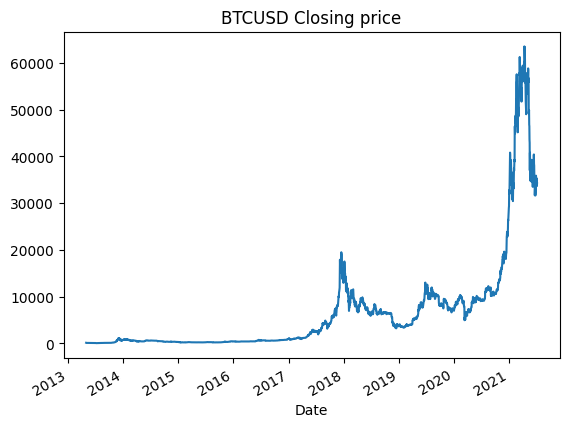

In [ ]:
_= df.Close.plot(title='BTCUSD Closing price')

We see that the series is not stationary but shows some upward trends.
We confirm this statistically with the Dickey-Fuller Test. If the p-value exceeds a certain threshold, we cannot reject the hypothesis that a unit root exists, and therefore the series is non-stationary.

In [ ]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df.Close)
# Result= the first number is associated with the test statistic, the second number is the p-value

print(f'Test ADG statistic: {result[0]}')
print(f'p-value: {result[1]*100}%')

Test ADG statistic: -0.7973098451195595
p-value: 81.99110033239155%


The p-value is 82%, so the probability that the unit root exists is 82%, and we cannot exclude this hypothesis at all.

In [ ]:
# Function for a signal on stationary and non-stationary series. We transmit the time series and assign the p-value at 5%
def test_ADF(x, pvalue=0.05):
  result = adfuller(x)
  if result[1]<= pvalue:
    return True
  return False

In [ ]:
test_ADF(df.Close)

False

The series is not stationary, and we need to make it stationary.

To do this, we take not the linear values but their logarithmic values.

<Axes: xlabel='Date'>

Is stationary? False


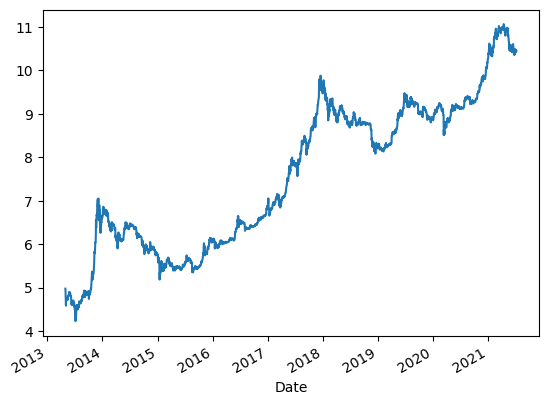

In [ ]:
# Check if this operation is enough to make the series stationary:

df['Close_log'] = np.log(df.Close)
df['Close_log'].plot()
print(f'Is stationary? {test_ADF(df["Close_log"])}')


We see that the trend with logarithmic values is not enough to make the series stationary.
Another operation we can perform is to apply a differentiation operator, which returns the  time series "shifted" with a differences we substract.
The number related to the difference we need to make the series stationary is a value used in ARIMA models (a parameter p associated to a order in the autoregressive model).
A second parameter in a ARIMA is the type of moving average to apply, which in this case is zero since an autoregressive model is sufficient.

Take the logarithmic values and apply the difference to shift the time series.

In [ ]:
# Proceed with decreasing the time series by itself, "shifted" by 1, meaning we shift all values by one position
df['Close_log_diff'] = df['Close_log'] - df['Close_log'].shift(1)


<Axes: xlabel='Date'>

Is stationary? True


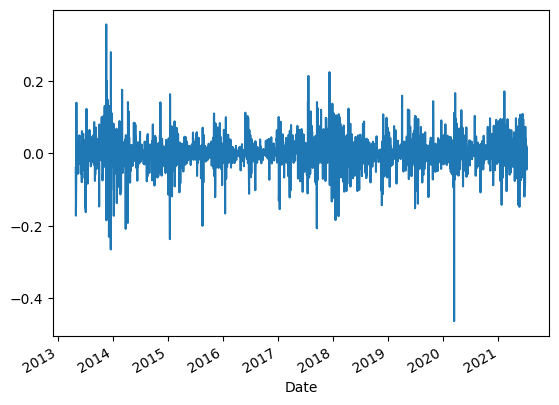

In [ ]:
# This operation naturally creates NaN values, which we need to drop
df.dropna(inplace=True)

df['Close_log_diff'].plot()
print(f'Is stationary? {test_ADF(df["Close_log_diff"])}')

This time, the test and the plot indicate that the time series is stationary, that means it has a zero mean.

This imply the series requires only one degree of differencing to become stationary: PARAMETER D = 1.
Now we need to determine how many orders the autoregressive model should have, that is how many "lags" back we need to look.


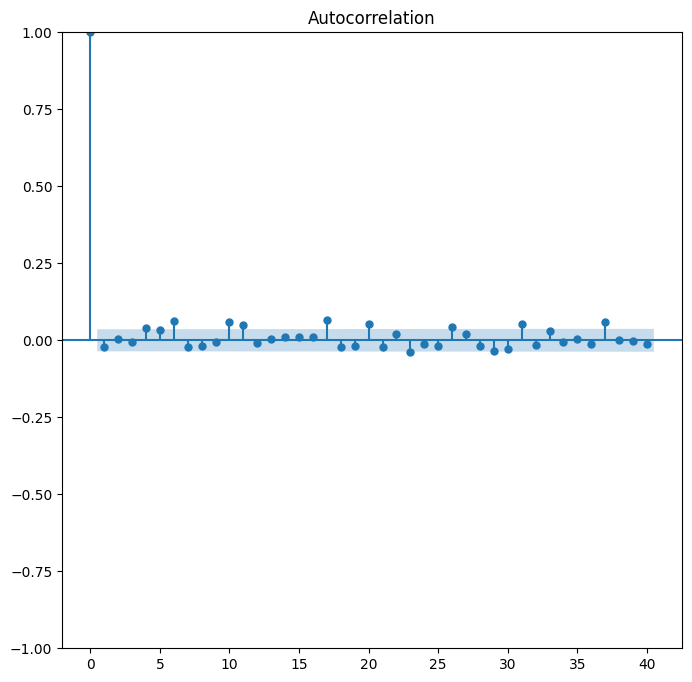

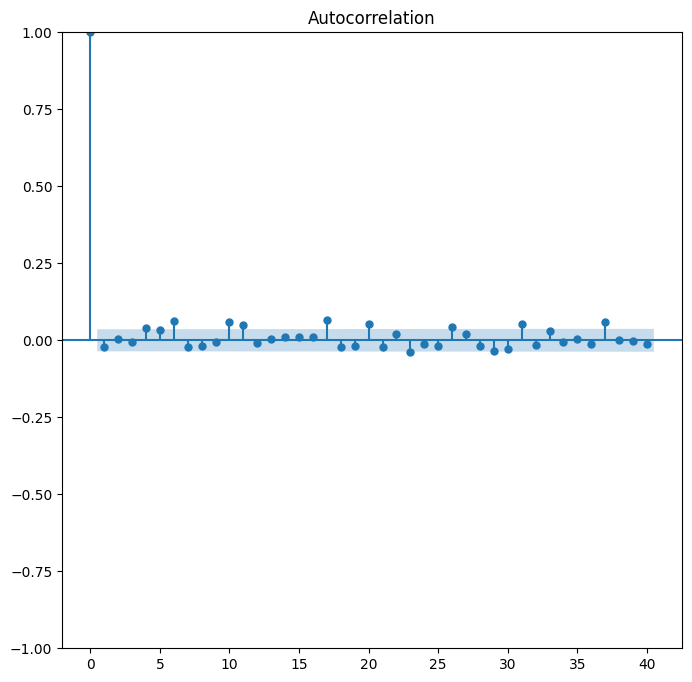

In [ ]:
# Import statmodel to see how many lags back we need to look (order p)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Create the figure, in which x-axis is the same
fig, ax = plt.subplots(1, sharex=True, figsize=(8,8))

# Plot the acf of close_log_diff, import the first 40 lags, and plot it on the ax axis
plot_acf(df['Close_log_diff'].dropna(), lags=40, ax=ax)

There is a strong correlation with the first lag, very high, that is maximum autocorrelation with itself. The other lags are slight.
So we take p=1 as a reference.

In [ ]:
# Create the autoregressive model of order 1, passing the time series and the tuple with order (1)
model = ARIMA(df.Close, order=(1, 1, 0))
# "d" (differencing to make the series stationary) = 1, order p = 1, moving average degree = 0 since the model is AUTO regressive
# We collect only AR, the first part of this ARIMA class, while M=0.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


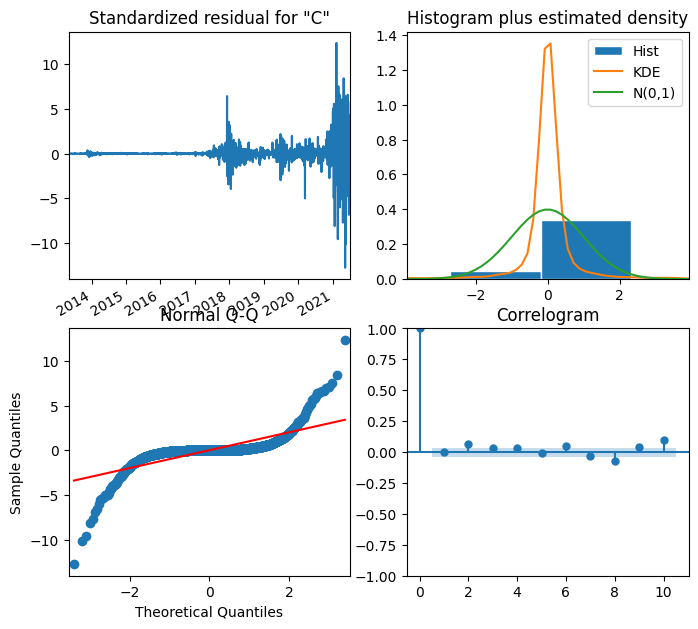

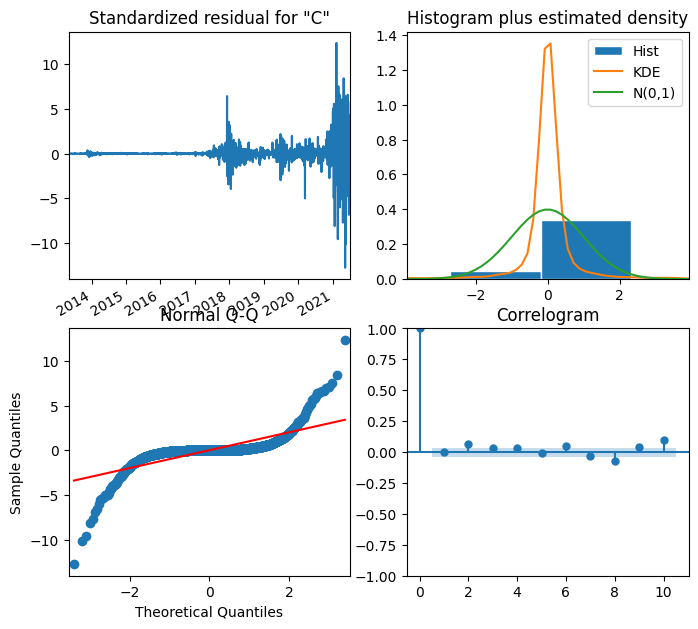

In [ ]:
# Plot to observe the model’s performance
model_fit=model.fit()
model_fit.plot_diagnostics(figsize=(8,8))

With this method, we plot the standardized residuals of the series, that means the errors obtained from the difference between the true value and the model prediction. We observe the histogram of our predictions (second plot), correlogram, and other forms of the same info.
It is necessary to note that the error should be close to 1, but in the first standardized residual plot, we see peaks in 2021. These are the upward trends we saw in the graph that represent model errors, that correspond to the out-of-place values, that in the graph show a positive trend for Bitcoin.

These errors help understand what the model we have built cannot capture all trends, especially extreme upward trends we saw in the first graph of time series we corrected.

# Build the model to predict the Bitcoin price for the next day

Mandatory operations:

- Split the time series into train and test subsets.
- In the time series model, the train set is the history, and the prediction is the price for the next day, compared with the test.
- Then add the test back into the train.
- Retrain the model with the entire historical dataset + next-day prediction.
- Try to predict the following day again and repeat the process in successive phases.

In [ ]:
# Assign 2500 values to the train

TIMESTP = 2500

train, test = df.Close[:TIMESTP], df.Close[TIMESTP:]

len(train), len(test)

(2500, 490)

In [ ]:
# Initial history
history = [x for x in train]

# Define lists of predictions we make
# y preds
y_hat = list() # We could name it y_hats as there are multiple lists
# actual y values
y = list() # We could name it ys as there are multiple lists
# Create a list for errors
erro_ls = list()

# Print predicted values against actual values
print('Printing Predicted vs Expected Values ...')
print('\n')

# Iterate an index over the test length range, that is all predictions we will perform
# For each step, train our model (ARIMA)
for t in range(len(test)):
    model = ARIMA(history, order=(1,1,0)).fit() # create the model and immediately fit it with history
    # After this operation, take its forecast:
    output = model.forecast() # Forecast produces a single prediction of a single value
    pred_value = output[0] # The predicted value is at index 0 of the output

    # Get the original value
    original_value = test[t] # The original value is taken from the test at index t
    # And add it to the history list ("append")
    history.append(original_value)

    # Calculate the error
    err = ((abs(pred_value - original_value)) / original_value) * 100
    erro_ls.append(err)
    y_hat.append(float(pred_value))
    y.append(float(original_value))


Printing Predicted vs Expected Values ...




In [ ]:
# Percentage of the sum of list containing errors, divided by the total length ("len") of erro_ls%
print('\n Mean Error in Predicting Test Case: %f' % (sum(erro_ls) / len(erro_ls)), '%')


 Mean Error in Predicting Test Case: 2.858838 %


<Figure size 800x600 with 0 Axes>

Text(0.5, 1.0, 'Expected VS Predicted Forecasting')

Text(0.5, 0, 'Day')

Text(0, 0.5, 'Closing Price')

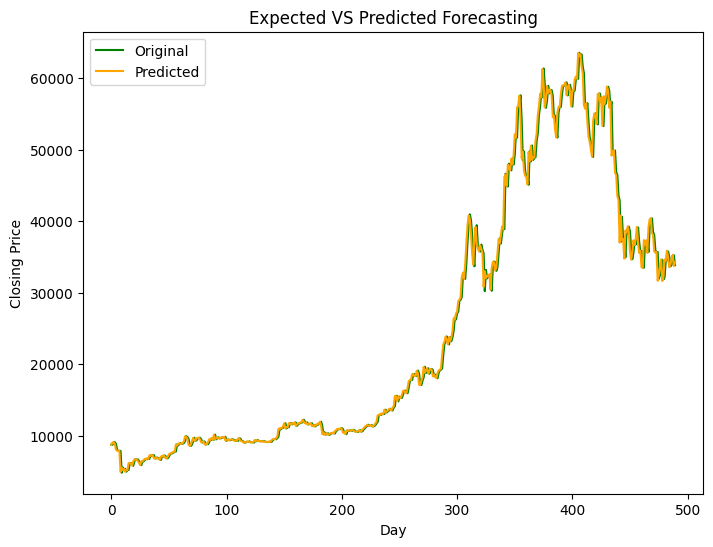

In [ ]:
plt.figure(figsize=(8,6))

test_day = [t for t in range(len(test))]
labels = ['Original', 'Predicted']
plt.plot(test_day, y_hat, color='green') #le pred y hat
plt.plot(test_day, y, color='orange') #le pred y
plt.title('Expected VS Predicted Forecasting')
plt.xlabel('Day')
plt.ylabel('Closing Price')
plt.legend(labels)
plt.show()


Over 490 days, we observe an average error of 2.86% determined by the deviation between predicted and actual values. Therefore, the model can effectively forecast one day ahead, with a very low error rate of around 2%.